
 CROSS-SEED LINEARITY & SPREAD DIAGNOSTICS (ARI & SILHOUETTE)
Dataset: 10x_human_lymph_node_A1        | Seeds Tested: 9
   • ARI Spread        -> Mean: 0.3360 | Std: 0.0029 | Min: 0.3298 | Max: 0.3398 | Spread (Max-Min): 0.0100
   • Silhouette Spread -> Mean: 0.3701 | Std: 0.0049 | Min: 0.3624 | Max: 0.3766 | Spread (Max-Min): 0.0142
   ► Linearity Verdict : Ultra-stable flat line (Near-zero variance, high seed independence).
Dataset: 10x_human_lymph_node_D1        | Seeds Tested: 9
   • ARI Spread        -> Mean: 0.3334 | Std: 0.0148 | Min: 0.3004 | Max: 0.3474 | Spread (Max-Min): 0.0470
   • Silhouette Spread -> Mean: 0.3354 | Std: 0.0142 | Min: 0.2976 | Max: 0.3499 | Spread (Max-Min): 0.0523
   ► Linearity Verdict : Near-linear trajectory across seeds (Good stability).
Dataset: Mouse_Brain_E11_S1             | Seeds Tested: 9
   • ARI Spread        -> Mean: 0.4654 | Std: 0.0244 | Min: 0.4085 | Max: 0.4899 | Spread (Max-Min): 0.0814
   • Silhouette Spread -> Mean: 0.2459 | Std: 0.00

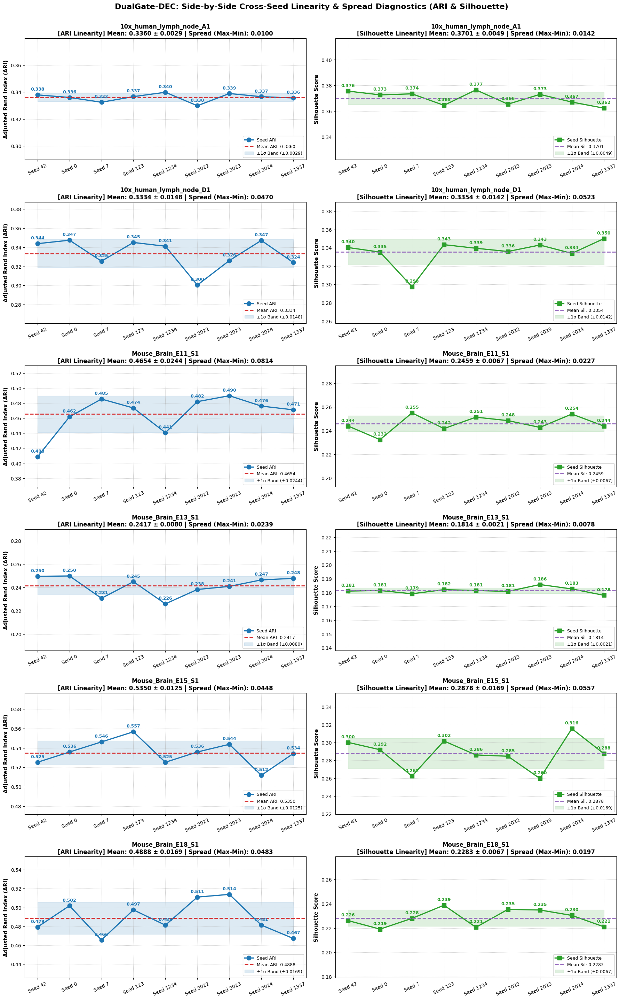

In [ ]:
# Cell 10: Cross-Seed Linearity & Metric Spread Suite (Side-by-Side: ARI vs Silhouette across Seeds)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Retrieve benchmark results from memory or saved CSV
RESULTS_DIR = os.path.join(OUTPUT_DIR, "results") if 'OUTPUT_DIR' in locals() else "DualGate_DEC_outputs/results"
VISUALS_DIR = os.path.join(OUTPUT_DIR, "visuals") if 'OUTPUT_DIR' in locals() else "DualGate_DEC_outputs/visuals"
os.makedirs(VISUALS_DIR, exist_ok=True)

csv_candidates = [
    os.path.join(RESULTS_DIR, "DualGate_DEC_benchmark_results.csv"),
    os.path.join(OUTPUT_DIR, "DualGate_DEC_benchmark_results.csv") if 'OUTPUT_DIR' in locals() else "DualGate_DEC_outputs/DualGate_DEC_benchmark_results.csv"
]
csv_fallback = next((p for p in csv_candidates if os.path.exists(p)), None)
if 'df_results' not in locals() or df_results is None or len(df_results) == 0:
    if csv_fallback is not None and os.path.exists(csv_fallback):
        df_results = pd.read_csv(csv_fallback)
        print(f"[Loaded] Retrieved {len(df_results)} benchmark rows from: {csv_fallback}")
    else:
        print("[Notice] No benchmark results found. Please execute Cell 9 first.")
        df_results = None

if df_results is not None and len(df_results) > 0:
    unique_datasets = df_results['dataset'].unique()
    n_datasets = len(unique_datasets)

    fig, axes = plt.subplots(n_datasets, 2, figsize=(18, 4.8 * n_datasets), squeeze=False)

    print("\n" + "="*85)
    print(" CROSS-SEED LINEARITY & SPREAD DIAGNOSTICS (ARI & SILHOUETTE)")
    print("="*85)

    for idx, d_name in enumerate(unique_datasets):
        sub_df = df_results[df_results['dataset'] == d_name].copy()

        # Format seeds on X-axis as categorical labels to ensure uniform spacing
        sub_df['seed_str'] = sub_df['seed'].astype(str)
        seeds_order = sub_df['seed_str'].tolist()
        x_indices = np.arange(len(seeds_order))

        # -------------------------------------------------------------
        # Left Subplot: Adjusted Rand Index (ARI) across all seeds
        # -------------------------------------------------------------
        ari_vals = sub_df['ARI'].values
        mean_ari = float(np.mean(ari_vals))
        std_ari = float(np.std(ari_vals))
        min_ari = float(np.min(ari_vals))
        max_ari = float(np.max(ari_vals))
        range_ari = max_ari - min_ari

        ax_ari = axes[idx, 0]
        # Line + Marker plot across seeds
        ax_ari.plot(x_indices, ari_vals, marker='o', markersize=9, linewidth=2.4, color='#1f77b4', label='Seed ARI')
        # Horizontal reference line for Mean ARI (shows linearity/flatness)
        ax_ari.axhline(mean_ari, color='#d62728', linestyle='--', linewidth=2.0, label=f'Mean ARI: {mean_ari:.4f}')
        # Shaded ±1 Std confidence band
        ax_ari.fill_between(x_indices, mean_ari - std_ari, mean_ari + std_ari, color='#1f77b4', alpha=0.15, label=f'±1σ Band (±{std_ari:.4f})')
        # Annotate each seed point with its exact value
        for x_i, y_i in zip(x_indices, ari_vals):
            ax_ari.annotate(f"{y_i:.3f}", (x_i, y_i), textcoords="offset points", xytext=(0, 9), ha='center', fontsize=9, fontweight='bold', color='#1f77b4')

        ax_ari.set_xticks(x_indices)
        ax_ari.set_xticklabels([f"Seed {s}" for s in seeds_order], fontsize=10, rotation=25)
        ax_ari.set_ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
        ax_ari.set_title(f"{d_name}\n[ARI Linearity] Mean: {mean_ari:.4f} ± {std_ari:.4f} | Spread (Max-Min): {range_ari:.4f}", fontsize=12, fontweight='bold')
        ax_ari.grid(True, linestyle=':', alpha=0.6)
        ax_ari.legend(loc='lower right', fontsize=9)
        y_pad = max(0.04, range_ari * 0.4)
        ax_ari.set_ylim([max(0.0, min_ari - y_pad), min(1.0, max_ari + y_pad)])

        # -------------------------------------------------------------
        # Right Subplot: Silhouette Score across all seeds
        # -------------------------------------------------------------
        sil_vals = sub_df['Silhouette'].values
        mean_sil = float(np.mean(sil_vals))
        std_sil = float(np.std(sil_vals))
        min_sil = float(np.min(sil_vals))
        max_sil = float(np.max(sil_vals))
        range_sil = max_sil - min_sil

        ax_sil = axes[idx, 1]
        # Line + Marker plot across seeds
        ax_sil.plot(x_indices, sil_vals, marker='s', markersize=9, linewidth=2.4, color='#2ca02c', label='Seed Silhouette')
        # Horizontal reference line for Mean Silhouette
        ax_sil.axhline(mean_sil, color='#9467bd', linestyle='--', linewidth=2.0, label=f'Mean Sil: {mean_sil:.4f}')
        # Shaded ±1 Std confidence band
        ax_sil.fill_between(x_indices, mean_sil - std_sil, mean_sil + std_sil, color='#2ca02c', alpha=0.15, label=f'±1σ Band (±{std_sil:.4f})')
        # Annotate each seed point with its exact value
        for x_i, y_i in zip(x_indices, sil_vals):
            ax_sil.annotate(f"{y_i:.3f}", (x_i, y_i), textcoords="offset points", xytext=(0, 9), ha='center', fontsize=9, fontweight='bold', color='#2ca02c')

        ax_sil.set_xticks(x_indices)
        ax_sil.set_xticklabels([f"Seed {s}" for s in seeds_order], fontsize=10, rotation=25)
        ax_sil.set_ylabel("Silhouette Score", fontsize=11, fontweight='bold')
        ax_sil.set_title(f"{d_name}\n[Silhouette Linearity] Mean: {mean_sil:.4f} ± {std_sil:.4f} | Spread (Max-Min): {range_sil:.4f}", fontsize=12, fontweight='bold')
        ax_sil.grid(True, linestyle=':', alpha=0.6)
        ax_sil.legend(loc='lower right', fontsize=9)
        y_pad_sil = max(0.04, range_sil * 0.4)
        ax_sil.set_ylim([max(-1.0, min_sil - y_pad_sil), min(1.0, max_sil + y_pad_sil)])

        # Detailed Linearity Diagnostic
        print(f"Dataset: {d_name:<30} | Seeds Tested: {len(seeds_order)}")
        print(f"   • ARI Spread        -> Mean: {mean_ari:.4f} | Std: {std_ari:.4f} | Min: {min_ari:.4f} | Max: {max_ari:.4f} | Spread (Max-Min): {range_ari:.4f}")
        print(f"   • Silhouette Spread -> Mean: {mean_sil:.4f} | Std: {std_sil:.4f} | Min: {min_sil:.4f} | Max: {max_sil:.4f} | Spread (Max-Min): {range_sil:.4f}")
        if range_ari <= 0.03:
            print("   ► Linearity Verdict : Ultra-stable flat line (Near-zero variance, high seed independence).")
        elif range_ari <= 0.06:
            print("   ► Linearity Verdict : Near-linear trajectory across seeds (Good stability).")
        else:
            print(f"   ► Linearity Verdict : Noticeable variation across seeds ({range_ari*100:.1f}% spread).")

    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.subplots_adjust(top=0.96, hspace=0.35)
    plt.suptitle("DualGate-DEC: Side-by-Side Cross-Seed Linearity & Spread Diagnostics (ARI & Silhouette)", fontsize=16, fontweight='bold', y=0.995)
    save_path = os.path.join(VISUALS_DIR, "DualGate_DEC_cross_seed_linearity.png")
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\n[Saved] Unified cross-seed linearity figure saved to: {save_path}")
    plt.show()



 SPATIAL DOMAIN PARTITIONING & MODALITY ATTENTION VISUALIZATION (6 DATASETS)
Dataset: 10x_human_lymph_node_A1        | Cells/Spots: 3484 | Domains Found: 10 | Attention Mapped: True
Dataset: 10x_human_lymph_node_D1        | Cells/Spots: 3359 | Domains Found: 11 | Attention Mapped: True
Dataset: Mouse_Brain_E11_S1             | Cells/Spots: 1263 | Domains Found: 8 | Attention Mapped: True
Dataset: Mouse_Brain_E13_S1             | Cells/Spots: 1777 | Domains Found: 12 | Attention Mapped: True
Dataset: Mouse_Brain_E15_S1             | Cells/Spots: 1949 | Domains Found: 12 | Attention Mapped: True
Dataset: Mouse_Brain_E18_S1             | Cells/Spots: 2129 | Domains Found: 14 | Attention Mapped: True

[Saved] Unified spatial domains & attention map figure (6 datasets) saved to: DualGate_DEC_outputs/visuals/DualGate_DEC_spatial_domains_and_attention.png


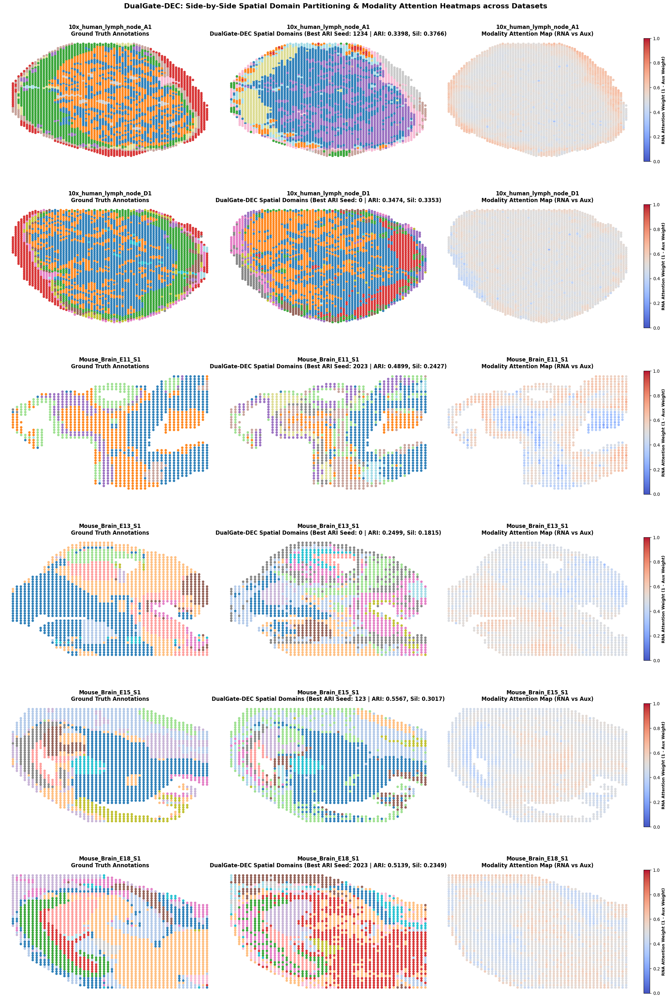


 SPATIAL DOMAIN & ATTENTION VISUALIZATION COMPLETE



In [ ]:
# Cell 12: Side-by-Side Spatial Domain & Attention Map Visualization for ALL Datasets (Unified Figure)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

RESULTS_DIR = os.path.join(OUTPUT_DIR, "results") if 'OUTPUT_DIR' in locals() else "DualGate_DEC_outputs/results"
VISUALS_DIR = os.path.join(OUTPUT_DIR, "visuals") if 'OUTPUT_DIR' in locals() else "DualGate_DEC_outputs/visuals"
os.makedirs(VISUALS_DIR, exist_ok=True)

datasets_to_plot = []
if 'all_dataset_adata' in locals() and len(all_dataset_adata) > 0:
    datasets_to_plot = list(all_dataset_adata.keys())
elif 'all_results' in locals() and len(all_results) > 0:
    datasets_to_plot = list(pd.DataFrame(all_results)['dataset'].unique())
elif 'all_histories' in locals() and len(all_histories) > 0:
    datasets_to_plot = list(all_histories.keys())
else:
    datasets_to_plot = [CHOICES[i][0] for i in DATASET_INDICES]

# Filter datasets that have loadable adata
loaded_adatas = {}
for d_name in datasets_to_plot:
    adata_plot = None
    if 'all_dataset_adata' in locals() and d_name in all_dataset_adata:
        adata_plot = all_dataset_adata[d_name]
    else:
        candidate_paths = [
            os.path.join(RESULTS_DIR, f"DualGate_DEC_adata_{d_name}.h5ad"),
            os.path.join(OUTPUT_DIR, f"DualGate_DEC_adata_{d_name}.h5ad") if 'OUTPUT_DIR' in locals() else "",
            f"DualGate_DEC_outputs/results/DualGate_DEC_adata_{d_name}.h5ad",
            f"DualGate_DEC_outputs/DualGate_DEC_adata_{d_name}.h5ad"
        ]
        for p in candidate_paths:
            if p and os.path.exists(p):
                try:
                    adata_plot = sc.read_h5ad(p)
                    break
                except Exception:
                    pass

    if adata_plot is None and 'dataset_name' in locals() and dataset_name == d_name:
        adata_plot = adata_hvg if 'adata_hvg' in locals() else adata_RNA

    if adata_plot is not None:
        loaded_adatas[d_name] = adata_plot

if len(loaded_adatas) == 0:
    print("[Notice] No spatial domain AnnData objects available to render. Please run Cell 9 first.")
else:
    valid_datasets = list(loaded_adatas.keys())
    n_datasets = len(valid_datasets)

    print("\n" + "="*85)
    print(f" SPATIAL DOMAIN PARTITIONING & MODALITY ATTENTION VISUALIZATION ({n_datasets} DATASETS)")
    print("="*85)

    # Render ONE unified figure containing all datasets (n_datasets rows x 3 columns)
    # Uses natural auto-aspect (without set_aspect('equal')) to prevent A1/D1 from shrinking
    fig, axes = plt.subplots(n_datasets, 3, figsize=(21, 5.2 * n_datasets), squeeze=False)

    for row_idx, d_name in enumerate(valid_datasets):
        adata_plot = loaded_adatas[d_name]

        coords = adata_plot.obsm.get('spatial', None)
        if coords is None:
            if 'dataset_name' in locals() and dataset_name == d_name and 'cell_positions' in locals():
                coords = cell_positions
            else:
                coords = np.zeros((adata_plot.n_obs, 2))

        gt_series = adata_plot.obs.get('ground_truth', None)
        gt_labels = pd.factorize(gt_series)[0] if gt_series is not None else np.zeros(coords.shape[0])

        domain_col = 'DualGate_DEC_domain' if 'DualGate_DEC_domain' in adata_plot.obs else ('domain' if 'domain' in adata_plot.obs else None)
        pred_labels = pd.factorize(adata_plot.obs[domain_col])[0] if (domain_col and domain_col in adata_plot.obs) else gt_labels

        has_att = 'mean_rna_attention' in adata_plot.obs
        mean_att = adata_plot.obs['mean_rna_attention'].values if has_att else None

        # Retrieve exact seed and benchmark metrics for panel subtitle
        row_metric_str = ""
        seed_label = adata_plot.uns.get('selected_seed', None)
        if 'df_results' in locals() and df_results is not None:
            sub_m = df_results[df_results['dataset'] == d_name]
            if len(sub_m) > 0:
                if seed_label is not None and (sub_m['seed'] == seed_label).any():
                    row_s = sub_m[sub_m['seed'] == seed_label].iloc[0]
                    row_metric_str = f" (Best ARI Seed: {seed_label} | ARI: {row_s['ARI']:.4f}, Sil: {row_s['Silhouette']:.4f})"
                else:
                    top_row = sub_m.sort_values(by='ARI', ascending=False).iloc[0]
                    row_metric_str = f" (Best ARI Seed: {top_row['seed']} | ARI: {top_row['ARI']:.4f}, Sil: {top_row['Silhouette']:.4f})"
        elif seed_label is not None:
            row_metric_str = f" (Seed: {seed_label})"

        # -------------------------------------------------------------
        # 1. Ground Truth Annotations (Col 0)
        # -------------------------------------------------------------
        ax0 = axes[row_idx, 0]
        is_bg = (gt_labels == -1)
        if is_bg.any():
            ax0.scatter(coords[is_bg, 0], coords[is_bg, 1], c='#e0e0e0', s=20, alpha=0.35, label='Unannotated')
        valid_mask = ~is_bg
        ax0.scatter(coords[valid_mask, 0], coords[valid_mask, 1], c=gt_labels[valid_mask], cmap='tab20', s=20, alpha=0.9)
        ax0.set_title(f"{d_name}\nGround Truth Annotations", fontsize=12, fontweight='bold')
        ax0.invert_yaxis()
        ax0.axis('off')

        # -------------------------------------------------------------
        # 2. DualGate-DEC Spatial Domains (Col 1)
        # -------------------------------------------------------------
        ax1 = axes[row_idx, 1]
        ax1.scatter(coords[:, 0], coords[:, 1], c=pred_labels, cmap='tab20', s=20, alpha=0.9)
        ax1.set_title(f"{d_name}\nDualGate-DEC Spatial Domains{row_metric_str}", fontsize=12, fontweight='bold')
        ax1.invert_yaxis()
        ax1.axis('off')

        # -------------------------------------------------------------
        # 3. Spatial Modality Attention Heatmap (Col 2)
        # -------------------------------------------------------------
        ax2 = axes[row_idx, 2]
        if has_att and mean_att is not None:
            sc_att = ax2.scatter(coords[:, 0], coords[:, 1], c=mean_att, cmap='coolwarm', s=20, vmin=0.0, vmax=1.0, alpha=0.95)
            cbar = plt.colorbar(sc_att, ax=ax2, fraction=0.046, pad=0.04)
            cbar.set_label('RNA Attention Weight (1 - Aux Weight)', fontsize=9, fontweight='bold')
            ax2.set_title(f"{d_name}\nModality Attention Map (RNA vs Aux)", fontsize=12, fontweight='bold')
        else:
            ax2.text(0.5, 0.5, "Attention weights not extracted", ha='center', va='center', fontsize=12, color='gray')
            ax2.set_title(f"{d_name}\nModality Attention Map", fontsize=12, fontweight='bold')
        ax2.invert_yaxis()
        ax2.axis('off')

        print(f"Dataset: {d_name:<30} | Cells/Spots: {coords.shape[0]} | Domains Found: {len(np.unique(pred_labels))} | Attention Mapped: {has_att}")

    # Unified overarching title with ample top padding
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.subplots_adjust(top=0.96, hspace=0.35)
    plt.suptitle("DualGate-DEC: Side-by-Side Spatial Domain Partitioning & Modality Attention Heatmaps across Datasets", fontsize=16, fontweight='bold', y=0.995)

    # Save ONE unified figure containing all datasets to the visuals directory
    save_path = os.path.join(VISUALS_DIR, "DualGate_DEC_spatial_domains_and_attention.png")
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\n[Saved] Unified spatial domains & attention map figure ({n_datasets} datasets) saved to: {save_path}")
    plt.show()

print("\n" + "="*85)
print(" SPATIAL DOMAIN & ATTENTION VISUALIZATION COMPLETE")
print("="*85 + "\n")



 LATENT EMBEDDING MANIFOLD VISUALIZATION (UMAP) (6 DATASETS - BEST ARI SEED)
Dataset: 10x_human_lymph_node_A1        | Manifold Spots: 3484 | Clusters: 10 | Attention Mapped: True
Dataset: 10x_human_lymph_node_D1        | Manifold Spots: 3359 | Clusters: 11 | Attention Mapped: True
Dataset: Mouse_Brain_E11_S1             | Manifold Spots: 1263 | Clusters: 8 | Attention Mapped: True
Dataset: Mouse_Brain_E13_S1             | Manifold Spots: 1777 | Clusters: 12 | Attention Mapped: True
Dataset: Mouse_Brain_E15_S1             | Manifold Spots: 1949 | Clusters: 12 | Attention Mapped: True
Dataset: Mouse_Brain_E18_S1             | Manifold Spots: 2129 | Clusters: 14 | Attention Mapped: True

[Saved] Unified latent UMAP manifold figure saved to: DualGate_DEC_outputs/visuals/DualGate_DEC_latent_umap.png


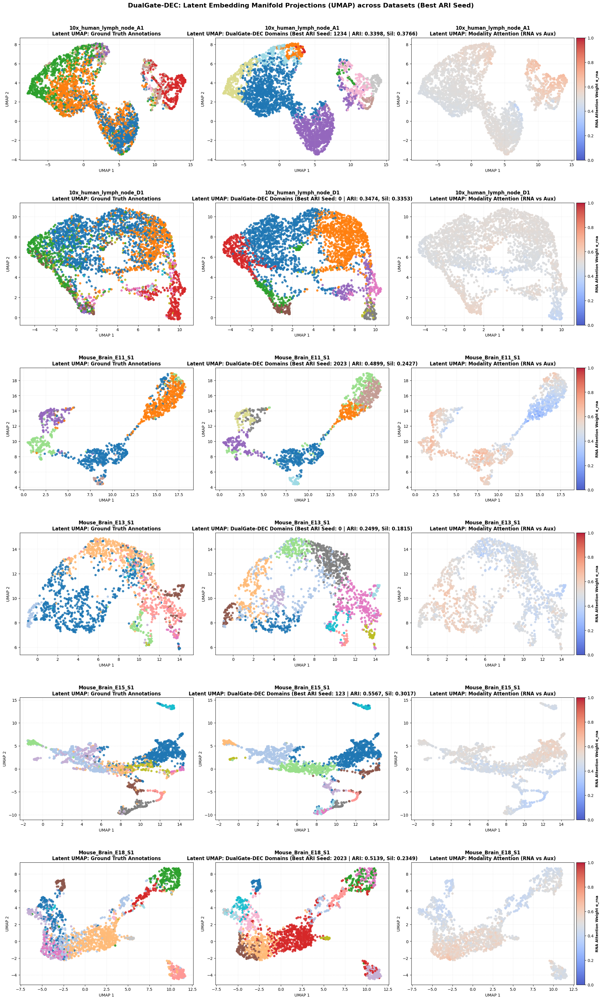

In [ ]:
# Cell 13: Latent Embedding Manifold Projections (Side-by-Side UMAP Suite for ALL Datasets)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from mpl_toolkits.axes_grid1 import make_axes_locatable

RESULTS_DIR = os.path.join(OUTPUT_DIR, "results") if 'OUTPUT_DIR' in locals() else "DualGate_DEC_outputs/results"
VISUALS_DIR = os.path.join(OUTPUT_DIR, "visuals") if 'OUTPUT_DIR' in locals() else "DualGate_DEC_outputs/visuals"
os.makedirs(VISUALS_DIR, exist_ok=True)

# Resolve datasets to render
datasets_to_plot = []
if 'all_dataset_adata' in locals() and len(all_dataset_adata) > 0:
    datasets_to_plot = list(all_dataset_adata.keys())
elif 'all_results' in locals() and len(all_results) > 0:
    datasets_to_plot = list(pd.DataFrame(all_results)['dataset'].unique())
elif 'all_histories' in locals() and len(all_histories) > 0:
    datasets_to_plot = list(all_histories.keys())
else:
    datasets_to_plot = [CHOICES[i][0] for i in DATASET_INDICES]

# Filter datasets that have loadable AnnData with embeddings
loaded_adatas = {}
for d_name in datasets_to_plot:
    adata_plot = None
    if 'all_dataset_adata' in locals() and d_name in all_dataset_adata:
        adata_plot = all_dataset_adata[d_name]
    else:
        candidate_paths = [
            os.path.join(RESULTS_DIR, f"DualGate_DEC_adata_{d_name}.h5ad"),
            os.path.join(OUTPUT_DIR, f"DualGate_DEC_adata_{d_name}.h5ad") if 'OUTPUT_DIR' in locals() else "",
            f"DualGate_DEC_outputs/results/DualGate_DEC_adata_{d_name}.h5ad",
            f"DualGate_DEC_outputs/DualGate_DEC_adata_{d_name}.h5ad"
        ]
        for p in candidate_paths:
            if p and os.path.exists(p):
                try:
                    adata_plot = sc.read_h5ad(p)
                    break
                except Exception:
                    pass

    if adata_plot is not None and 'DualGate_DEC_emb' in adata_plot.obsm:
        loaded_adatas[d_name] = adata_plot

if len(loaded_adatas) == 0:
    print("[Notice] No latent embeddings found to compute UMAP. Please execute Cell 9 first.")
else:
    valid_datasets = list(loaded_adatas.keys())
    n_datasets = len(valid_datasets)

    print("\n" + "="*85)
    print(f" LATENT EMBEDDING MANIFOLD VISUALIZATION (UMAP) ({n_datasets} DATASETS - BEST ARI SEED)")
    print("="*85)

    # Compute UMAP for each dataset if not already precomputed
    for d_name in valid_datasets:
        adata_curr = loaded_adatas[d_name]
        if 'X_umap' not in adata_curr.obsm:
            print(f"   • Computing 2D UMAP projection for {d_name}...")
            sc.pp.neighbors(adata_curr, use_rep='DualGate_DEC_emb', n_neighbors=15, metric='cosine', random_state=42)
            sc.tl.umap(adata_curr, min_dist=0.3, spread=1.0, random_state=42)

    # Render ONE unified figure containing all datasets (n_datasets rows x 3 columns)
    fig, axes = plt.subplots(n_datasets, 3, figsize=(21, 5.8 * n_datasets), squeeze=False)

    for row_idx, d_name in enumerate(valid_datasets):
        adata_plot = loaded_adatas[d_name]
        umap_coords = adata_plot.obsm['X_umap']

        gt_series = adata_plot.obs.get('ground_truth', None)
        gt_labels = pd.factorize(gt_series)[0] if gt_series is not None else np.zeros(umap_coords.shape[0])

        domain_col = 'DualGate_DEC_domain' if 'DualGate_DEC_domain' in adata_plot.obs else ('domain' if 'domain' in adata_plot.obs else None)
        pred_labels = pd.factorize(adata_plot.obs[domain_col])[0] if (domain_col and domain_col in adata_plot.obs) else gt_labels

        has_att = 'mean_rna_attention' in adata_plot.obs
        mean_att = adata_plot.obs['mean_rna_attention'].values if has_att else None

        # Retrieve exact best-ARI seed and benchmark metrics for panel subtitle
        row_metric_str = ""
        seed_label = adata_plot.uns.get('selected_seed', None)
        if 'df_results' in locals() and df_results is not None:
            sub_m = df_results[df_results['dataset'] == d_name]
            if len(sub_m) > 0:
                if seed_label is not None and (sub_m['seed'] == seed_label).any():
                    row_s = sub_m[sub_m['seed'] == seed_label].iloc[0]
                    row_metric_str = f" (Best ARI Seed: {seed_label} | ARI: {row_s['ARI']:.4f}, Sil: {row_s['Silhouette']:.4f})"
                else:
                    top_row = sub_m.sort_values(by='ARI', ascending=False).iloc[0]
                    row_metric_str = f" (Best ARI Seed: {top_row['seed']} | ARI: {top_row['ARI']:.4f} | Sil: {top_row['Silhouette']:.4f})"
        elif seed_label is not None:
            row_metric_str = f" (Best ARI Seed: {seed_label})"

        # -------------------------------------------------------------
        # 1. Ground Truth Annotations in Latent UMAP (Col 0)
        # -------------------------------------------------------------
        ax0 = axes[row_idx, 0]
        is_bg = (gt_labels == -1)
        if is_bg.any():
            ax0.scatter(umap_coords[is_bg, 0], umap_coords[is_bg, 1], c='#e0e0e0', s=16, alpha=0.35, label='Unannotated')
        valid_mask = ~is_bg
        ax0.scatter(umap_coords[valid_mask, 0], umap_coords[valid_mask, 1], c=gt_labels[valid_mask], cmap='tab20', s=22, alpha=0.85)
        ax0.set_title(f"{d_name}\nLatent UMAP: Ground Truth Annotations", fontsize=12, fontweight='bold')
        ax0.set_xlabel("UMAP 1", fontsize=10)
        ax0.set_ylabel("UMAP 2", fontsize=10)
        ax0.grid(True, linestyle=':', alpha=0.4)

        # -------------------------------------------------------------
        # 2. DualGate-DEC Discovered Spatial Domains in Latent UMAP (Col 1)
        # -------------------------------------------------------------
        ax1 = axes[row_idx, 1]
        ax1.scatter(umap_coords[:, 0], umap_coords[:, 1], c=pred_labels, cmap='tab20', s=22, alpha=0.85)
        ax1.set_title(f"{d_name}\nLatent UMAP: DualGate-DEC Domains{row_metric_str}", fontsize=12, fontweight='bold')
        ax1.set_xlabel("UMAP 1", fontsize=10)
        ax1.set_ylabel("UMAP 2", fontsize=10)
        ax1.grid(True, linestyle=':', alpha=0.4)

        # -------------------------------------------------------------
        # 3. Spatial Modality Attention Heatmap on Latent UMAP (Col 2)
        # -------------------------------------------------------------
        ax2 = axes[row_idx, 2]
        if has_att and mean_att is not None:
            sc_att = ax2.scatter(umap_coords[:, 0], umap_coords[:, 1], c=mean_att, cmap='coolwarm', s=22, vmin=0.0, vmax=1.0, alpha=0.9)
            divider = make_axes_locatable(ax2)
            cax = divider.append_axes("right", size="5%", pad=0.08)
            cbar = fig.colorbar(sc_att, cax=cax)
            cbar.set_label('RNA Attention Weight α_rna', fontsize=9, fontweight='bold')
            ax2.set_title(f"{d_name}\nLatent UMAP: Modality Attention (RNA vs Aux)", fontsize=12, fontweight='bold')
        else:
            ax2.text(0.5, 0.5, "Attention weights not extracted", ha='center', va='center', fontsize=12, color='gray')
            ax2.set_title(f"{d_name}\nLatent UMAP: Modality Attention", fontsize=12, fontweight='bold')
        ax2.set_xlabel("UMAP 1", fontsize=10)
        ax2.set_ylabel("UMAP 2", fontsize=10)
        ax2.grid(True, linestyle=':', alpha=0.4)

        print(f"Dataset: {d_name:<30} | Manifold Spots: {umap_coords.shape[0]} | Clusters: {len(np.unique(pred_labels))} | Attention Mapped: {has_att}")

    # Unified Overarching Title with breathing room
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.subplots_adjust(top=0.96, hspace=0.35)
    plt.suptitle("DualGate-DEC: Latent Embedding Manifold Projections (UMAP) across Datasets (Best ARI Seed)", fontsize=16, fontweight='bold', y=0.995)
    save_path = os.path.join(VISUALS_DIR, "DualGate_DEC_latent_umap.png")
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\n[Saved] Unified latent UMAP manifold figure saved to: {save_path}")
    plt.show()
